# US airline delays: where they start, how they spread, what they cost
Walk-through of the analysis behind the README. SQL runs live against the DuckDB warehouse built by `src/run_pipeline.py`; the bootstrap and the risk model are read from `reports/`.

In [1]:
import os, sys, json, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, Markdown, display
from src import config, data
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
pd.set_option('display.width', 160)
results = json.loads(config.RESULTS_JSON.read_text())
T = lambda name: pd.read_csv(f'reports/tables/{name}.csv')

## 1. Data quality and scale

In [2]:
display(T('quality_checks'))
display(data.row_counts())
results['network']

,rule,severity,failures
0,Flight dates inside the study window,hard,0
1,Every study month is present,hard,0
2,Scheduled times parse to minutes 0-1439,hard,0
3,Not cancelled or diverted but no arrival time ...,soft,1
4,Arrival delay flag matches arrival delay of 15...,hard,0
5,Cancelled flights have a cancellation code,hard,0
6,Delay causes add up to the arrival delay (dela...,soft,160
7,Tail number missing,soft,30990
8,Scheduled arrival day offset outside 0-1 (time...,soft,2
9,"Same carrier, flight number, date and origin t...",soft,1


{'flights': 14082099,
 'tail_legs': 13817220,
 'turns': 9925386,
 'propagation': 9925386,
 'airports': 9053}

{'scheduled': 14082099,
 'operated': 13817220,
 'cancelled': 224729,
 'cancel_rate': 0.01595848743855586,
 'on_time_rate': 0.7801834232935424,
 'arr_delay_minutes': 234129234.0,
 'arr_delay_min_per_flight': 16.944742430098096,
 'carriers': 15,
 'carriers_full_window': 12,
 'airports': 103,
 'days': 730,
 'first_date': '2024-10-01',
 'last_date': '2026-09-30'}

,year_month,scheduled,cancel_rate,on_time_rate,carrier_minutes,weather_minutes,nas_minutes,security_minutes,late_aircraft_minutes
0,2024-10,615497,0.0102,0.8680,"2,093,737.0000","165,524.0000","797,518.0000","8,954.0000","1,832,453.0000"
1,2024-11,575404,0.0046,0.8533,"1,947,420.0000","287,549.0000","1,153,004.0000","8,279.0000","1,879,940.0000"
2,2024-12,590581,0.0070,0.7885,"3,029,692.0000","659,435.0000","1,573,667.0000","13,722.0000","3,553,542.0000"
3,2025-01,539747,0.0302,0.8121,"2,510,886.0000","629,972.0000","1,381,827.0000","10,550.0000","2,410,759.0000"
4,2025-02,504884,0.0147,0.7923,"2,513,734.0000","486,199.0000","1,666,833.0000","8,734.0000","2,735,511.0000"
5,2025-03,600872,0.0115,0.8041,"2,761,618.0000","492,193.0000","1,832,804.0000","10,673.0000","3,281,080.0000"
6,2025-04,583950,0.0084,0.8034,"2,563,581.0000","433,723.0000","1,743,517.0000","14,791.0000","3,085,757.0000"
7,2025-05,605648,0.0105,0.7640,"2,990,564.0000","708,753.0000","2,647,632.0000","11,326.0000","3,861,591.0000"
8,2025-06,611575,0.0159,0.7174,"4,095,591.0000","893,051.0000","2,707,009.0000","20,281.0000","5,264,576.0000"
9,2025-07,631428,0.0245,0.7111,"4,477,900.0000","1,057,529.0000","2,985,238.0000","15,270.0000","5,880,680.0000"


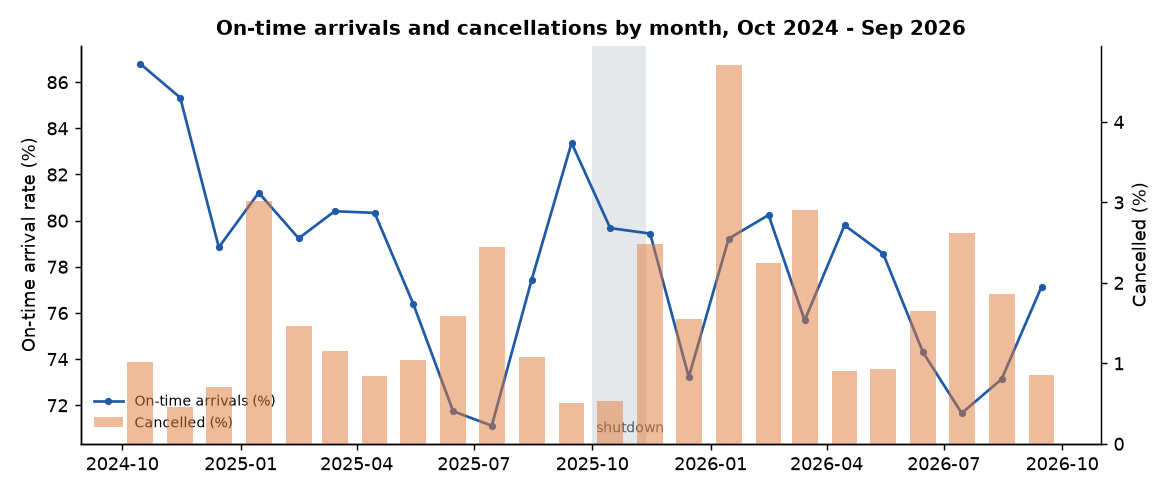

In [3]:
display(T('monthly_causes'))
display(Image(filename='reports/figures/01_monthly_on_time.png'))

## 2. Causes of delay
Carriers code every arrival delay of 15+ minutes into five causes. Late-arriving aircraft is delay carried from an earlier flight of the same aircraft.

Late-arriving aircraft     0.3949
Carrier                    0.3290
National Aviation System   0.2120
Extreme weather            0.0627
Security                   0.0014
dtype: float64

delay multiplier: 1.653


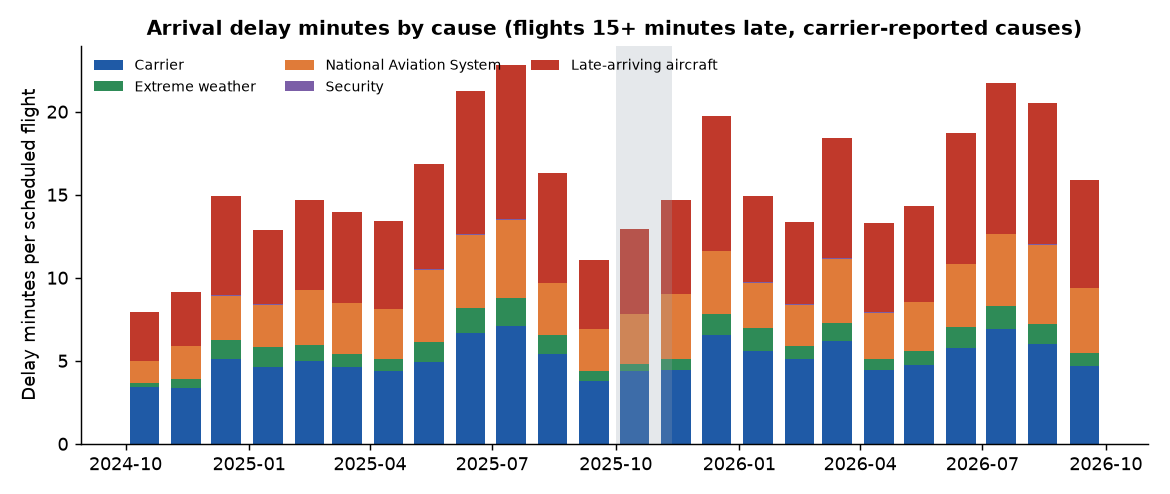

In [4]:
display(pd.Series(results['causes']['shares']).sort_values(ascending=False))
print('delay multiplier:', round(results['causes']['delay_multiplier'], 3))
display(Image(filename='reports/figures/02_delay_causes.png'))

,dep_hour,scheduled,dep_delay15_rate,arr_delay15_rate,arr_delay_min_per_flight,late_aircraft_share,cancel_rate
0,0,21870,0.2039,0.1618,13.2848,0.3767,0.0143
1,1,6943,0.1909,0.1694,14.3800,0.3734,0.0176
2,2,2487,0.2236,0.2049,15.0980,0.4640,0.0145
3,3,1467,0.2114,0.1815,17.7580,0.5122,0.0198
4,4,551,0.1713,0.1639,13.4254,0.4041,0.0145
5,5,390761,0.0747,0.0860,9.4485,0.1351,0.0150
6,6,968315,0.0783,0.0979,9.3830,0.1353,0.0158
7,7,1029005,0.0985,0.1244,9.9323,0.1583,0.0130
8,8,973802,0.1196,0.1421,10.5077,0.2349,0.0122
9,9,797063,0.1466,0.1577,11.2127,0.3071,0.0115


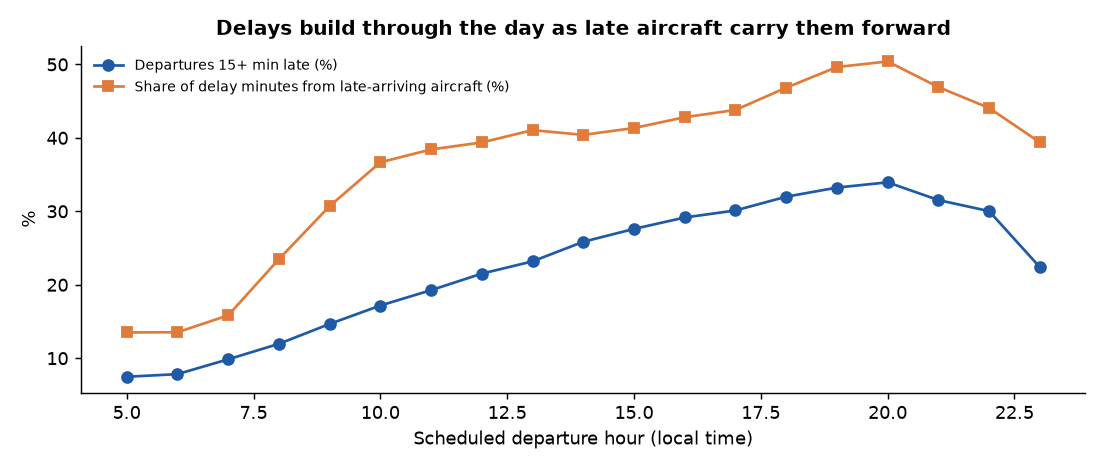

In [5]:
display(T('hourly'))
display(Image(filename='reports/figures/03_delay_by_hour.png'))

## 3. Aircraft rotations and delay propagation
`sql/03_rotations.sql` links each flight to the previous flight of the same aircraft with a window function, then estimates how much of each departure delay was carried in from the inbound flight.

In [6]:
data.query('SELECT carrier, tail, origin, dest, sched_turn, actual_turn, prev_arr_delay, dep_delay, slack, propagated FROM propagation WHERE prev_arr_delay > 30 LIMIT 8')

,carrier,tail,origin,dest,sched_turn,actual_turn,prev_arr_delay,dep_delay,slack,propagated
0,B6,N3229J,FLL,RDU,49.0000,53.0000,58.0000,62.0000,8.0000,50.0000
1,B6,N3229J,BOS,DAB,98.0000,76.0000,91.0000,69.0000,57.0000,34.0000
2,B6,N3229J,DAB,BOS,55.0000,44.0000,50.0000,39.0000,14.0000,36.0000
3,B6,N3229J,ORD,BOS,53.0000,42.0000,175.0000,164.0000,12.0000,163.0000
4,B6,N3232J,ATL,FLL,55.0000,94.0000,49.0000,88.0000,14.0000,35.0000
5,B6,N3232J,FLL,JFK,55.0000,39.0000,134.0000,118.0000,14.0000,118.0000
6,B6,N3232J,DCA,BOS,61.0000,48.0000,98.0000,85.0000,20.0000,78.0000
7,B6,N3241J,CHS,JFK,55.0000,53.0000,63.0000,61.0000,14.0000,49.0000


In [7]:
display(T('min_turn'))
display(data.query('16_propagation_check.sql'))
display(data.query('17_propagation_totals.sql'))

,carrier,min_turn,forced_turns
0,WN,33.0000,363947
1,AA,38.0000,189454
2,DL,42.0000,164450
3,OO,23.0000,155028
4,UA,42.0000,112466
5,YX,25.0000,62071
6,OH,24.0000,61984
7,F9,41.0000,58902
8,MQ,25.0000,54015
9,B6,41.0000,52942


,delayed_outbound_turns,correlation,agreement_share,reported_given_estimated,estimated_given_reported,propagated_minutes,late_aircraft_minutes
0,2241977,0.8467,0.8469,0.9027,0.8214,"59,071,193.0000","59,572,162.0000"


,turns,share_inbound_late,share_with_propagated,share_propagated_15,propagated_minutes,departure_delay_minutes,propagated_share_of_departure_delay,median_sched_turn,share_turns_45_or_less,propagated_share_from_turns_45_or_less
0,9925386,0.1897,0.1534,0.0965,"62,086,218.0000","152,468,252.0000",0.4072,55.0000,0.3134,0.4271


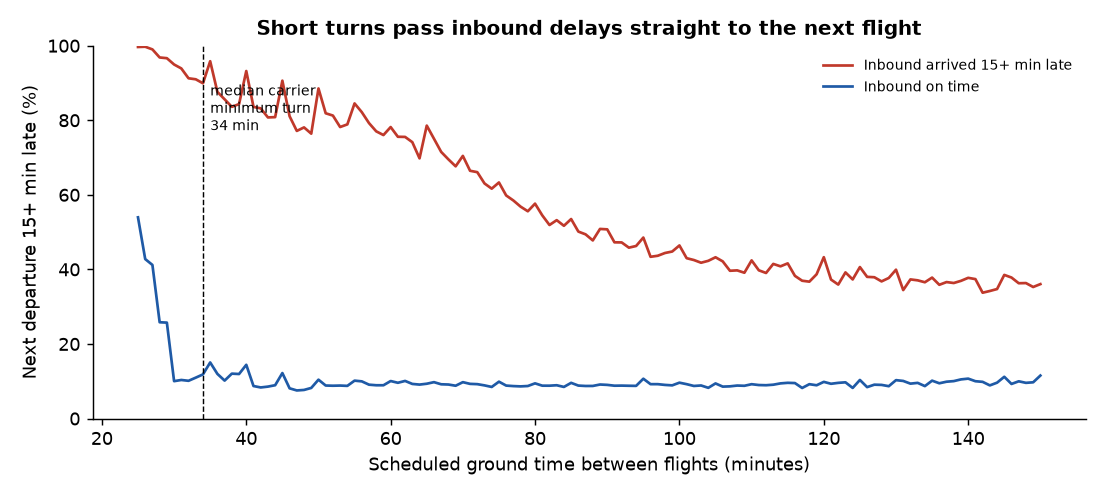

,carrier,turns,median_sched_turn,min_turn,share_slack_15_or_less,share_with_propagated,propagated_minutes,own_departure_minutes
0,WN,2148675,45.0000,33.0000,0.6587,0.2161,"14,844,579.0000","19,127,088.0000"
1,DL,1445112,66.0000,42.0000,0.2476,0.1074,"6,422,907.0000","12,360,816.0000"
2,AA,1242222,60.0000,38.0000,0.3367,0.1529,"8,217,535.0000","14,158,188.0000"
3,OO,1241914,47.0000,23.0000,0.1483,0.1301,"8,135,565.0000","9,009,558.0000"
4,UA,1041303,72.0000,42.0000,0.0831,0.0984,"4,898,212.0000","10,183,117.0000"
5,YX,508757,46.0000,25.0000,0.2604,0.1359,"3,025,288.0000","3,746,267.0000"
6,MQ,444973,45.0000,25.0000,0.4625,0.1489,"2,300,838.0000","2,777,695.0000"
7,AS,398115,60.0000,34.0000,0.1381,0.1114,"1,301,083.0000","3,334,238.0000"
8,OH,354797,44.0000,24.0000,0.4237,0.1931,"3,406,238.0000","3,806,827.0000"
9,F9,302634,60.0000,41.0000,0.4025,0.1981,"3,084,880.0000","3,691,572.0000"


In [8]:
display(Image(filename='reports/figures/04_turn_propagation.png'))
display(T('carrier_turns'))

## 4. Carrier scorecard
On-time arrival rates with 95% intervals from resampling whole days.

,carrier_name,scheduled,on_time_rate,on_time_ci_low,on_time_ci_high,cancel_rate,late_aircraft_share,delay_multiplier,full_window
0,Southwest Airlines,2778445,0.7767,0.7700,0.7845,0.0087,0.5115,2.0473,True
1,Delta Air Lines,2060141,0.8119,0.8058,0.8185,0.0128,0.2983,1.4251,True
2,American Airlines,1963128,0.7505,0.7440,0.7572,0.0193,0.4628,1.8615,True
3,SkyWest Airlines,1688615,0.7911,0.7864,0.7961,0.0147,0.2113,1.2679,True
4,United Airlines,1622121,0.7905,0.7842,0.7970,0.0092,0.3677,1.5814,True
5,Republic Airways,703481,0.7962,0.7874,0.8056,0.0362,0.3729,1.5947,True
6,Envoy Air,613139,0.8045,0.7970,0.8116,0.0205,0.4400,1.7856,True
7,Alaska Airlines,562491,0.7883,0.7825,0.7940,0.0114,0.3873,1.6321,True
8,PSA Airlines,493243,0.7374,0.7293,0.7456,0.0448,0.4921,1.9690,True
9,JetBlue,475619,0.7345,0.7254,0.7447,0.0254,0.4341,1.7671,True


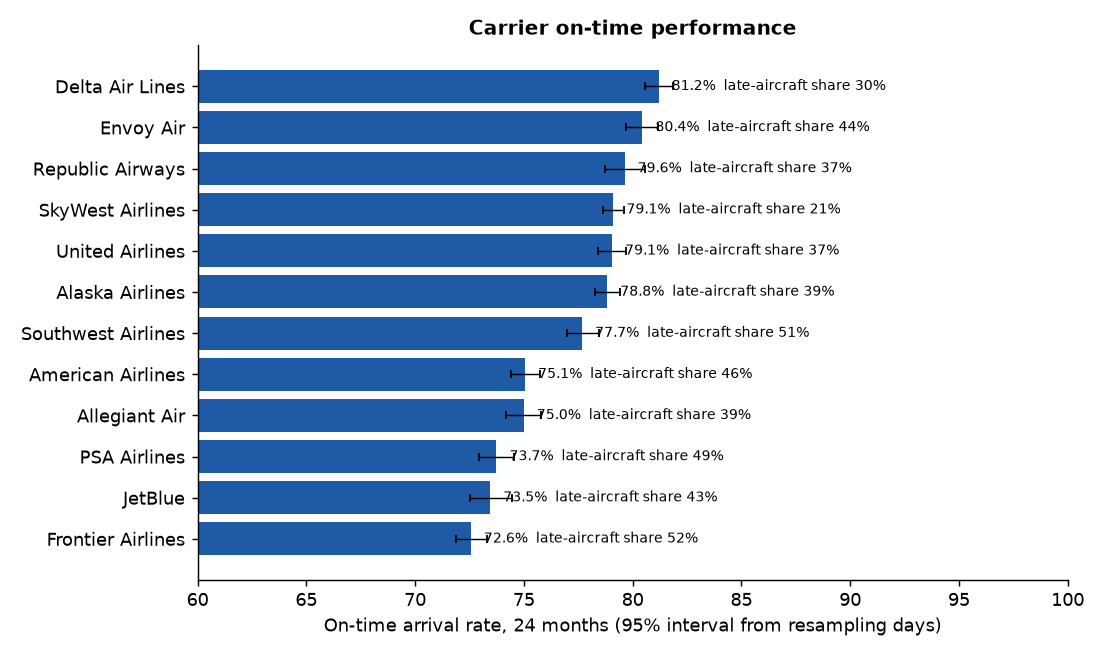

In [9]:
sc = T('carrier_scorecard')
display(sc[['carrier_name', 'scheduled', 'on_time_rate', 'on_time_ci_low', 'on_time_ci_high', 'cancel_rate', 'late_aircraft_share', 'delay_multiplier', 'full_window']])
display(Image(filename='reports/figures/05_carrier_on_time.png'))

## 5. The 2025 shutdown
Daily metrics against the same weekday 364 days earlier, regressed on the shutdown and flight-cut periods with Newey-West errors.

,period,nas_min_per_flight,nas_min_per_flight_prior,cancel_rate,cancel_rate_prior,on_time_rate,on_time_rate_prior,scheduled,scheduled_prior
0,"Shutdown, before flight cuts",3.0892,1.4953,0.0059,0.0029,0.8017,0.8628,"19,287.4333","19,525.6667"
1,Shutdown with flight cuts,7.5250,1.3510,0.0705,0.0090,0.7206,0.8771,"18,818.8333","18,894.0000"
2,Flight cuts after shutdown,1.7898,1.3999,0.0196,0.0011,0.8735,0.8855,"19,436.2500","19,723.0000"
3,After,3.4376,2.5144,0.0147,0.0057,0.7568,0.8072,"18,907.9556","19,119.7111"


,sample,metric,period,effect,ci_low,ci_high,p,baseline_yoy,days
0,Excluding Hurricane Milton week,nas_min_per_flight,"Shutdown, before flight cuts",0.6707,-0.3944,1.7358,0.2171,0.9232,85
1,Excluding Hurricane Milton week,nas_min_per_flight,Shutdown with flight cuts,5.2508,2.5955,7.9060,0.0001,0.9232,85
2,Excluding Hurricane Milton week,nas_min_per_flight,Flight cuts after shutdown,-0.5333,-1.4269,0.3603,0.2421,0.9232,85
3,Excluding Hurricane Milton week,cancel_rate,"Shutdown, before flight cuts",-0.0061,-0.0117,-0.0004,0.0350,0.0090,85
4,Excluding Hurricane Milton week,cancel_rate,Shutdown with flight cuts,0.0524,0.0357,0.0692,0.0000,0.0090,85
5,Excluding Hurricane Milton week,cancel_rate,Flight cuts after shutdown,0.0095,0.0007,0.0182,0.0342,0.0090,85
6,Excluding Hurricane Milton week,nas_cancel_rate,"Shutdown, before flight cuts",0.0007,-0.0011,0.0025,0.4403,0.0009,85
7,Excluding Hurricane Milton week,nas_cancel_rate,Shutdown with flight cuts,0.0493,0.0431,0.0555,0.0000,0.0009,85
8,Excluding Hurricane Milton week,nas_cancel_rate,Flight cuts after shutdown,0.0155,0.0086,0.0225,0.0000,0.0009,85
9,Excluding Hurricane Milton week,on_time_rate,"Shutdown, before flight cuts",-0.0107,-0.0576,0.0361,0.6533,-0.0504,85


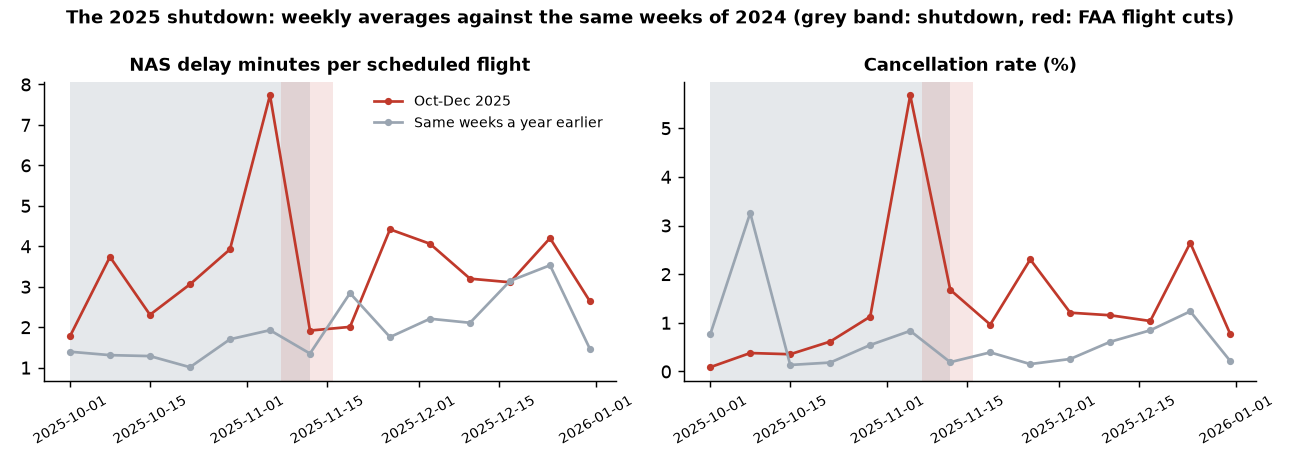

In [10]:
display(T('shutdown_period_means'))
display(T('shutdown_effects'))
display(Image(filename='reports/figures/06_shutdown_weekly.png'))

In [11]:
T('shutdown_airports').sort_values('nas_change', ascending=False).head(10)

,airport,departures_2025,departures_2024,cancel_rate_2025,cancel_rate_2024,dep_delay15_2025,dep_delay15_2024,nas_min_per_dep_2025,nas_min_per_dep_2024,nas_change,cancel_change
13,LGA,16661,19551,0.0398,0.0051,0.2551,0.1118,9.3623,1.1214,8.2410,0.0347
20,JFK,12342,14778,0.0242,0.0048,0.2019,0.1080,7.2037,1.0947,6.1090,0.0194
15,EWR,14729,15567,0.0329,0.0090,0.2303,0.1600,8.6110,2.6850,5.9260,0.0239
9,MCO,18380,17278,0.0132,0.0548,0.2417,0.1436,6.0554,0.9701,5.0853,-0.0416
40,CMH,5458,5275,0.0128,0.0102,0.1878,0.0946,5.7109,1.0677,4.6432,0.0026
28,TPA,8518,8480,0.0156,0.0762,0.2076,0.1356,4.9710,1.1381,3.8329,-0.0606
22,MIA,12084,11822,0.0141,0.0135,0.2223,0.1511,4.6513,0.9966,3.6547,0.0005
26,FLL,9449,9572,0.0155,0.0080,0.2283,0.1499,5.2064,1.6410,3.5653,0.0074
32,RDU,6774,7341,0.0152,0.0067,0.2004,0.1236,5.4963,2.0643,3.4320,0.0085
12,DCA,16975,16742,0.0208,0.0053,0.2404,0.1219,4.1682,1.0287,3.1396,0.0155


## 6. Disruption-risk model
LightGBM on schedule-time features, trained on Oct 2024 - Mar 2026 and tested on Apr - Sep 2026.

In [12]:
m = results['model']
{k: m[k] for k in ('train_rows', 'test_rows', 'base_rate_test', 'auc', 'auc_baseline', 'brier', 'brier_climatology', 'top_decile_rate', 'top_decile_lift')}

{'train_rows': 5000000,
 'test_rows': 3627856,
 'base_rate_test': 0.25667170913068216,
 'auc': 0.720812676397784,
 'auc_baseline': 0.648351321466976,
 'brier': 0.16578963466353036,
 'brier_climatology': 0.1916929341131916,
 'top_decile_rate': 0.6028374854597476,
 'top_decile_lift': 2.348671333905437}

,feature,gain,share
0,origin,"1,261,409.7383",0.1945
1,planned_turn,"1,091,713.1278",0.1683
2,dest,"1,083,820.0987",0.1671
3,dep_hour,"1,003,370.4791",0.1547
4,month,"570,817.4878",0.0880
5,planned_leg,"521,789.8410",0.0804
6,carrier,"338,587.5248",0.0522
7,arr_hour,"336,654.4890",0.0519
8,dow,"231,798.8155",0.0357
9,distance,"24,042.2665",0.0037


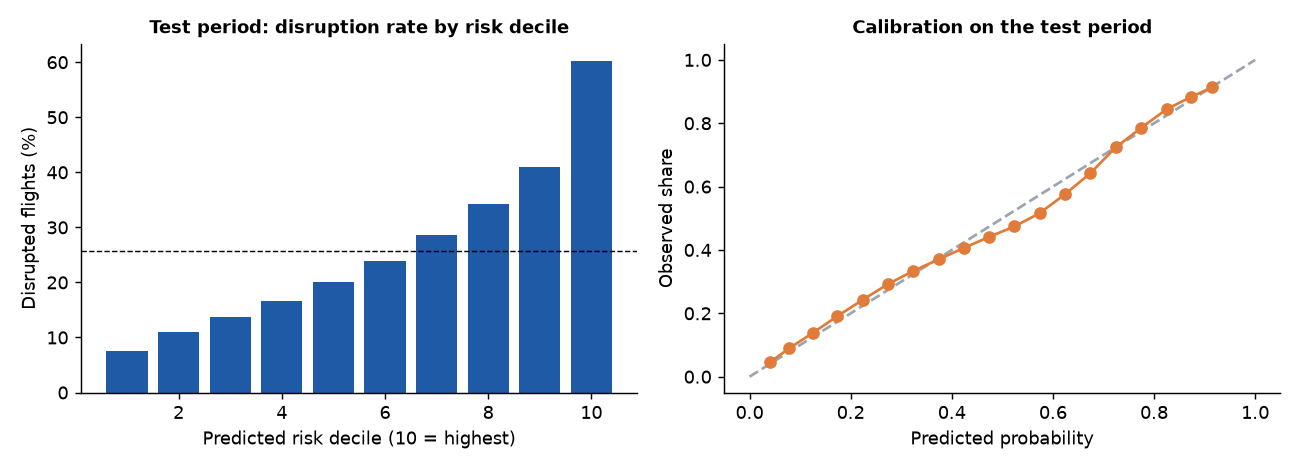

In [13]:
display(T('model_importance').head(10))
display(Image(filename='reports/figures/08_model_lift_calibration.png'))

## 7. Turn-buffer scenarios

,carrier,time_window,threshold,buffer,turns_buffered,propagated_now,propagated_after,minutes_avoided
120,All,All day,45,5,3110765,"26,516,505.0000","23,461,507.0000","3,054,998.0000"
121,All,All day,45,10,3110765,"26,516,505.0000","20,769,279.0000","5,747,226.0000"
122,All,All day,45,15,3110765,"26,516,505.0000","18,457,338.0000","8,059,167.0000"
123,All,All day,45,20,3110765,"26,516,505.0000","16,473,231.0000","10,043,274.0000"
124,All,All day,45,30,3110765,"26,516,505.0000","13,262,581.0000","13,253,924.0000"
125,All,All day,60,5,5898669,"45,809,607.0000","40,754,619.0000","5,054,988.0000"
126,All,All day,60,10,5898669,"45,809,607.0000","36,301,319.0000","9,508,288.0000"
127,All,All day,60,15,5898669,"45,809,607.0000","32,457,701.0000","13,351,906.0000"
128,All,All day,60,20,5898669,"45,809,607.0000","29,135,926.0000","16,673,681.0000"
129,All,All day,60,30,5898669,"45,809,607.0000","23,711,718.0000","22,097,889.0000"


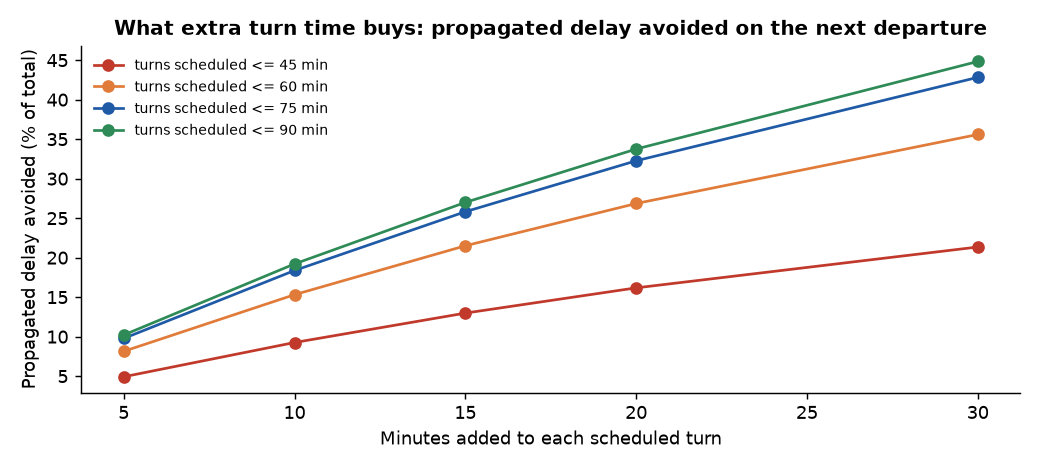

In [14]:
b = T('buffer_scenarios')
display(b[b.carrier == 'All'])
display(Image(filename='reports/figures/09_buffer_scenarios.png'))

## 8. Memo

In [15]:
display(Markdown(open('reports/memo.md').read()))

# Memo: where US flight delays start and what extra turn time is worth

**To:** VP Operations Planning · **Data:** BTS on-time performance, 14,082,099 flights, 2024-10-01 to 2026-09-30

**What we found**

- **14,082,099 scheduled flights from 2024-10-01 to 2026-09-30:** 78.0% arrived on time (less than 15 minutes late), 1.6% were cancelled, and operated flights arrived 16.9 minutes late on average, 234.1 million minutes in total.
- **Late-arriving aircraft is the largest cause of delay: 39.5% of delay minutes,** ahead of carrier causes (32.9%), the National Aviation System (21.2%) and extreme weather (6.3%). Each minute of original delay grows to 1.65 minutes as it moves through aircraft rotations.
- **Delay builds through the day.** 7.8% of 6 am departures leave 15+ minutes late; by 20:00 it is 33.9%. The late-aircraft share of delay minutes rises from 14% to 50%.
- **Scheduled turn time decides whether a delay spreads.** When the inbound flight arrived 15+ minutes late, 94% of departures after a 30-40 minute turn also left late, against 44% after a 90-120 minute turn (and 13% when the inbound was on time). Across 9.9 million linked aircraft turns, 41% of departure delay minutes were carried in from the inbound flight; turns of 45 minutes or less are 31% of turns and carry 43% of propagated minutes. The estimate agrees with the carriers' own late-aircraft coding on 85% of delayed flights (correlation 0.85).
- **Delta Air Lines has the highest on-time rate of the 12 carriers that reported all 24 months** (81.2%, 95% interval 80.6% to 81.8%) and Frontier Airlines the lowest (72.6%). Frontier Airlines turns delay over most: 52% of its delay minutes come from late aircraft (multiplier 2.06, median scheduled turn 60 minutes) against 21% at SkyWest Airlines (1.27).
- **A blanket schedule buffer does not pay for itself at the airline level.** Adding 15 minutes to every turn scheduled at 60 minutes or less would avoid 22% of propagated delay (13.4 million minutes over 24 months) but use 88.5 million aircraft minutes. Priced at A4A's 2025 cost rates, the airline saves $339 million a year in gate time and spends $607 million on aircraft time (net -$268 million); it breaks even only if extra ground time costs less than $7.65 a minute. Passengers would save $502 million a year in time. The same buffer on afternoon turns only (departures from 15:00) breaks even at $10.50 a minute.
- **The 2025 shutdown hit hardest once the FAA cut flights.** In the five weeks before the cuts, the year-over-year change in NAS delay was +0.7 minutes per flight above its post-shutdown level (95% CI -0.4 to 1.7), too small to tell apart from zero, and the cancellation rate moved by -0.61 points (95% CI -1.17 to -0.04). During the shutdown days with flight cuts (7-12 November), NAS delay rose by +5.3 minutes per flight (95% CI 2.6 to 7.9), cancellations by +5.2 points (95% CI 3.57 to 6.92) and the on-time rate fell by 10.6 points. After the shutdown ended, NAS delay was back near normal (-0.5 minutes, 95% CI -1.4 to 0.4). The largest NAS increases were at LGA, JFK, EWR. Hurricane Milton (landfall 9 October 2024) cancelled many flights in the comparison year; with those days kept, the pre-cut cancellation change is -1.33 points.
- **Schedule data alone flags the riskiest flights.** A LightGBM model trained on October 2024 - March 2026 and tested on 3,627,856 flights from April to September 2026 scores an AUC of 0.721 (baseline on carrier, hour and month: 0.648). The top risk decile was disrupted 60% of the time against 26% on average (2.3x) and the bottom decile 7%. The planned turn before the flight is the second most useful feature (17% of gain).

**What to do**

1. Protect the first wave: departures before 8 am are rarely late, and every minute they lose is carried through the day. Track first-departure on-time rate by hub as a daily operating KPI.
2. Add turn time where inbound delays are common, not across the board. A blanket 15-minute buffer on turns of 60 minutes or less breaks even only below $7.65 a ground minute; limited to afternoon turns the break-even rises to $10.50. Test the targeted version first at the airports with the most propagated delay, and confirm the true cost of an aircraft ground minute (the model's default is $13.71).
3. Use the risk model at schedule-build time: flights in the top risk decile are worth a longer planned turn, a spare aircraft or crew at the hub, or a swap with a lower-risk rotation.
4. Review Frontier Airlines' turn standards against SkyWest Airlines': the gap in delay multiplier (2.06 against 1.27) is mostly scheduled slack, which the airline controls.
5. Keep a playbook for air traffic control staffing events: during the FAA flight cuts, NAS delay and cancellations rose sharply within days. Early, planned cancellations on thin routes protect the hub banks.

**Caveats:** industry-average cost rates; carrier-coded causes; first-order buffer benefits.
